# Lab: Data Visualization and Visual Thinking

The U.S. Bureau of Transportation Statistics collects information about scheduled domestic flights. In this lab, you will use the ideas from **Data Visualization and Visual Thinking** to examine a documented sample of 5,000 completed, non-diverted flights from May 2026.


## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [1]:
# Write your code here.
import pandas as pd

flights = pd.read_csv('data/bts_flights_may_2026_sample.csv')



Display the first five rows of the DataFrame.


In [2]:
# Write your code here.
flights.head()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [3]:
# Write your code here.
flights.tail()

,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [4]:
# Write your code here.
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer: There are 5,000 observations (rows) in this dataFrame.


Count the missing values in every feature.


In [6]:
# Write your code here.
flights.isnull().sum()

airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | str | categorical | 0 |
| `origin_city` |str  | categorical | 0 |
| `destination_city` | str |  categorical| 0 |
| `distance_miles` | int64 | quantitative |0  |
| `arrival_delay_minutes` |int64  | quantitative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [7]:
# Write your code here.
destination_counts = flights['destination_city'].value_counts()
destination_counts

destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


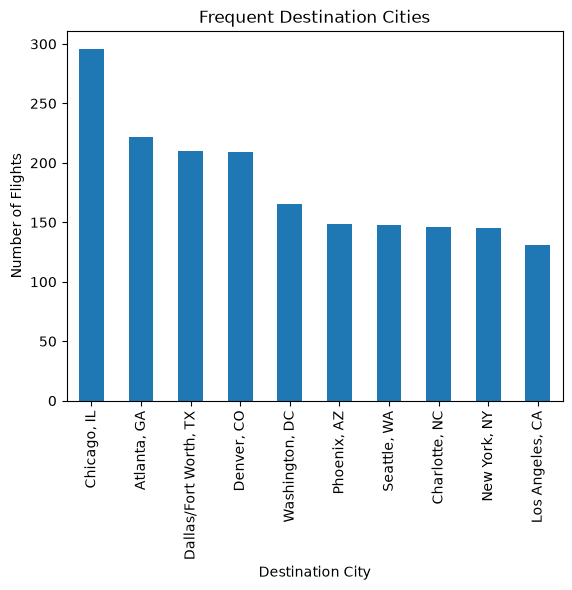

In [12]:
# Write your code here.
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind = 'bar')
plt.title('Frequent Destination Cities')
plt.ylabel('Number of Flights')
plt.xlabel('Destination City')  

plt.show()

**Which destination city is most common in the sample?**

Your answer: The most visited city was Chicago, Il.


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


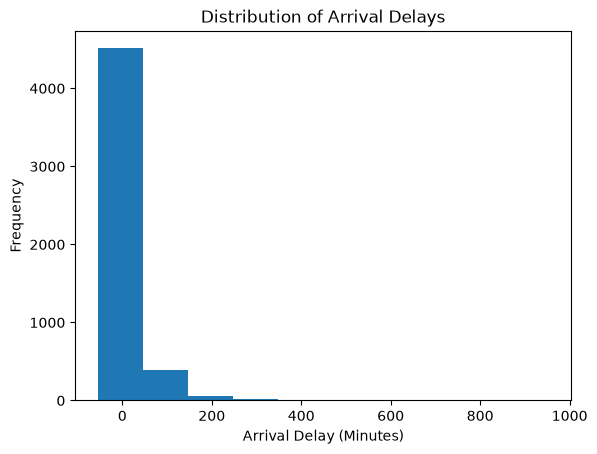

In [13]:
# Write your code here.
flights['arrival_delay_minutes'].plot(kind='hist')

plt.title('Distribution of Arrival Delays')
plt.ylabel('Frequency')
plt.xlabel('Arrival Delay (Minutes)')

plt.show()

**Approximately what arrival-delay value appears most common?**

Your answer: 0 minutes has more flights than any other coming in at 4500. 



**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer: the range runs from about -50 to 1000 minutes. The flights past 400 are barely visible.


**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:Skewed - right skewed 


Display a numerical summary of `arrival_delay_minutes`.


In [14]:
# Write your code here.
flights['arrival_delay_minutes'].describe()

count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [15]:
# Write your code here.
flights['arrival_delay_minutes'].mode()

0   -8
Name: arrival_delay_minutes, dtype: int64

**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: It was very close i estimated 0 and it gave me -8


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer:The range was -55 to 953 , I estimated -50 -1000 so my estimate was also close for the range


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer:The mean 6.10 is greater than the median -6


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer:The histogram is right skewed because few extremely late flights pull the mean 6.10 higher than the median -6.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


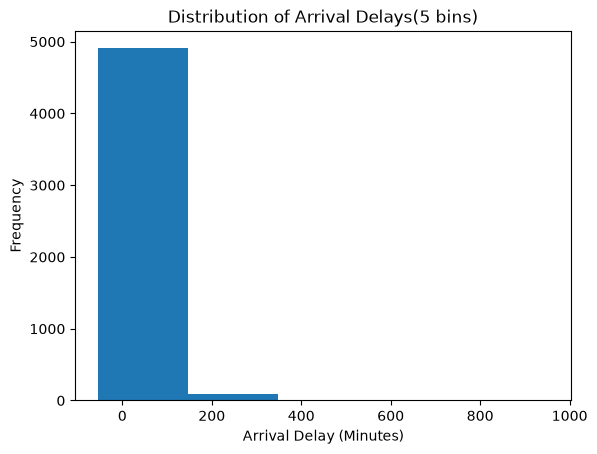

In [18]:
# Write your code here.
flights['arrival_delay_minutes'].plot(kind='hist', bins =5)

plt.title('Distribution of Arrival Delays(5 bins)')
plt.ylabel('Frequency')
plt.xlabel('Arrival Delay (Minutes)')

plt.show()


Re-create the arrival-delay histogram using exactly 25 bins.


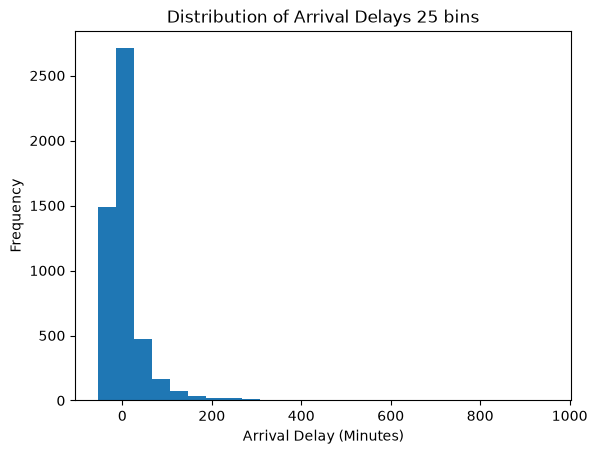

In [19]:
# Write your code here.
flights['arrival_delay_minutes'].plot(kind='hist', bins=25)

plt.title('Distribution of Arrival Delays 25 bins')
plt.ylabel('Frequency')
plt.xlabel('Arrival Delay (Minutes)')

plt.show()

**What changed when the number of bins was reduced to 5?**

Your answer:The bins became more wider, so mostly all flights merged into one bar.



**What changed when the number of bins was increased to 25?**

Your answer:The bins became narrower


**Which bin setting communicates the distribution most clearly?**

Your answer:The 25 bins communicated the distribution better


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


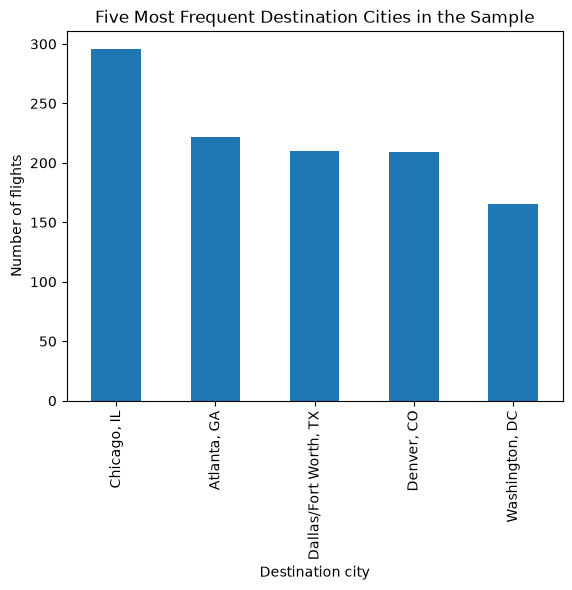

In [20]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


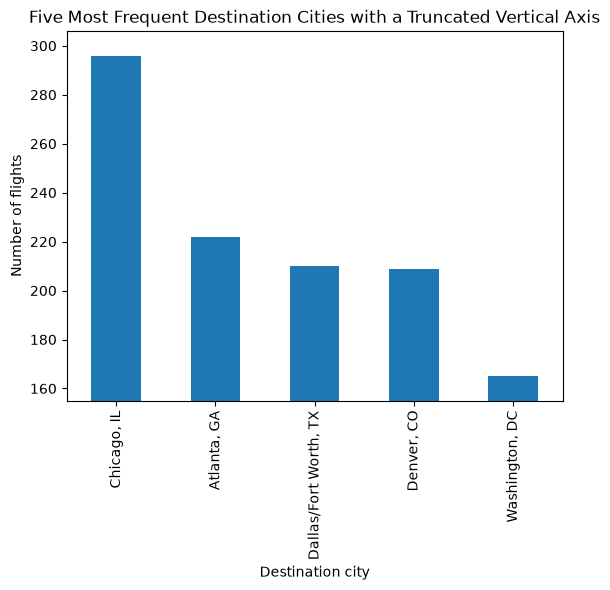

In [21]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer:The truncated axis makes the differences between the destination cities look much larger than they actually are because the graph does not start at zero.


**Which chart communicates the counts more honestly?**

Your answer:The original chart communicates the counts more honestly because the vertical axis starts at zero, giving a more accurate representation of the differences between the cities.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: may 2026


**Which flights were eligible to be included in the sample?**

Your answer:The completed dommestic flights that were not canceled or diverted


**Which flights and records were excluded before the sample was selected?**

Your answer:Canceled flights, diverted flights, and any flight records with missing information in one or more of the five selected features were excluded before the sample was selected.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer:No because the records with missing values were already removed before the sample was taken


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer:Since canceled and diverted flights were not included in the sample, we don't have their information to compare. So the results only tell us about completed flights, not all flights.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: The histograms because it groups times into intervals


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer:I would use a pie chart because it shows the proportion of flights that were early, on time, or delayed as parts of the whole sample.


**Which chart would you use to show the distribution of flight distances?**

Your answer:A histogram because it shows flight distances across different ranges


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer:


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [7]:
# Load and inspect your chosen dataset here.
import pandas as pd
wine_df = pd.read_csv('data/wine_dataset.csv')

wine_df.head()

wine_df.shape

wine_df.info()

wine_df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   class                         178 non-null    int64  
 1   Alcohol                       178 non-null    float64
 2   Malic acid                    178 non-null    float64
 3   Ash                           178 non-null    float64
 4   Alcalinity of ash             178 non-null    float64
 5   Magnesium                     178 non-null    int64  
 6   Total phenols                 178 non-null    float64
 7   Flavanoids                    178 non-null    float64
 8   Nonflavanoid phenols          178 non-null    float64
 9   Proanthocyanins               178 non-null    float64
 10  Color intensity               178 non-null    float64
 11  Hue                           178 non-null    float64
 12  OD280/OD315 of diluted wines  178 non-null    float64
 13  Proline         

class                           0
Alcohol                         0
Malic acid                      0
Ash                             0
Alcalinity of ash               0
Magnesium                       0
Total phenols                   0
Flavanoids                      0
Nonflavanoid phenols            0
Proanthocyanins                 0
Color intensity                 0
Hue                             0
OD280/OD315 of diluted wines    0
Proline                         0
dtype: int64

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
|---|---|---|---|---:|
| class | Wine category (1, 2, or 3) | Categorical | int64 | 0 |
| Alcohol | Alcohol content of the wine | Quantitative | float64 | 0 |
| Malic acid | Amount of malic acid in the wine | Quantitative | float64 | 0 |
| Ash | Amount of ash in the wine | Quantitative | float64 | 0 |
| Alcalinity of ash | Alkalinity measurement of the ash | Quantitative | float64 | 0 |
| Magnesium | Amount of magnesium in the wine | Quantitative | int64 | 0 |
| Total phenols | Total amount of phenolic compounds | Quantitative | float64 | 0 |
| Flavanoids | Amount of flavonoid compounds | Quantitative | float64 | 0 |
| Nonflavanoid phenols | Amount of nonflavonoid phenolic compounds | Quantitative | float64 | 0 |
| Proanthocyanins | Amount of proanthocyanins in the wine | Quantitative | float64 | 0 |
| Color intensity | Measurement of the wine's color intensity | Quantitative | float64 | 0 |
| Hue | Measurement of the wine's color hue | Quantitative | float64 | 0 |
| OD280/OD315 of diluted wines | Ratio of absorbance readings | Quantitative | float64 | 0 |
| Proline | Amount of proline in the wine | Quantitative | int64 | 0 |

**Missing-value codes or other data preparation, if applicable:**

Your answer: All features have 0 missing values



### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


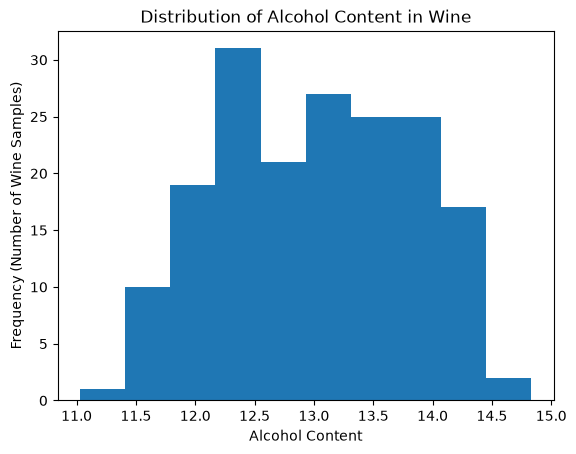

In [10]:
# Create and label your quantitative-feature visualization here.
import matplotlib.pyplot as plt

wine_df['Alcohol'].plot(kind='hist')

plt.title('Distribution of Alcohol Content in Wine')
plt.ylabel('Frequency (Number of Wine Samples)')
plt.xlabel('Alcohol Content')

plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:I chose Alcohol because it is a quantitative feature, and a histogram is appropriate because it shows how the alcohol measurements are distributed across the wine samples.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:The histogram shows how the alcohol measurements vary across the 178 wine samples, including where most of the values are grouped and how spread out the measurements are.


### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


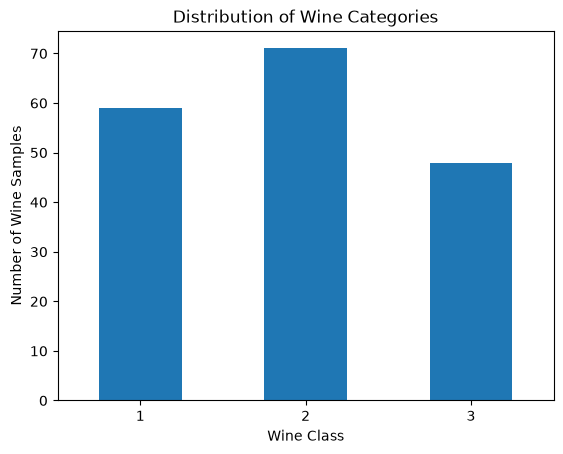

In [11]:
# Create and label your categorical-feature visualization here.
class_counts = wine_df["class"].value_counts().sort_index()

class_counts.plot(kind="bar")

plt.title("Distribution of Wine Categories")
plt.xlabel("Wine Class")
plt.ylabel("Number of Wine Samples")
plt.xticks(rotation=0)
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:I chose class because it represents three different wine categories. A bar chart is appropriate because it allows me to compare the number of wine samples in each category.

**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:The bar chart shows how the 178 wine samples are divided among the three categories. It makes it easy to identify which wine class has the most samples and which has the fewest.


## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:chatgpt
- What I asked it to help with:Organizing my dataset features into a table and identifying their meanings, data types, storage types, and missing values.
- One suggestion I checked against my code, chart, or output:Checking the Pandas .info() and .isnull().sum() results against the feature table.
- What I accepted, modified, or rejected—and why:I accepted the guidance because it helped me accurately document each feature and understand how the data was organized.

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:


## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
